# Projeto 1 – Data Preparation
## Neonatal Vital Signs and Clinical Conditions (Grupo 5)

Este notebook implementa o **capítulo 4 do relatório**, secção a secção. Parte dos ficheiros originais e produz os conjuntos de dados finais usados na modelação.

| Secção do relatório | O que este notebook faz | Resultado |
|---|---|---|
| 4.1 Selecionar dados | Fixa as regras de inclusão/exclusão (Tabela 24) | Constantes no início |
| 4.2 Limpar dados | Aplica os 10 passos da Tabela 25, contando os registos afetados | `sinais_vitais_limpo.csv`, `patologias_limpo.csv`, `relatorio_limpeza.csv` |
| 4.3 Construir dados | Calcula o tempo de internamento e os atributos derivados (Tabela 26) | `episodios_resumo.csv` |
| 4.4 Integrar dados | Junta sinais vitais e patologias por problema de data mining | `dataset_classificacao.csv`, `dataset_regressao.csv`, `dataset_clustering.csv` |
| 4.5 Formatar dados | snake_case, datas ISO, 4 casas decimais, alvos 0/1, UTF-8 | — |
| 4.6 Conjunto final | Verifica tudo e compara com os números escritos no relatório | Tabela de verificação |

O notebook **01_data_understanding** só observa os dados. Este é o único que os altera, e os ficheiros originais nunca são modificados.

No fim há uma célula que compara cada número calculado com o valor escrito no relatório. Se alguém mudar uma regra, essa célula mostra logo que números do relatório têm de ser atualizados.

## 0. Configuração

Todas as regras e limiares que o relatório define estão neste bloco, num só sítio. Para mudar uma regra (por exemplo, o limiar de perfusão baixa, que a secção 4.3.1 diz que deve ser validado com os docentes), basta alterar aqui e correr o notebook outra vez.

In [1]:
# --- Bibliotecas ---
import re                      # expressões regulares (normalizar textos)
import unicodedata             # remover acentos ao comparar nomes de patologias
from pathlib import Path       # caminhos de ficheiros que funcionam em Windows e macOS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

# --- Pastas ---
# Pasta-raiz do projeto: sobe a partir da pasta atual até encontrar data/raw
# (funciona quer o notebook seja aberto a partir da raiz quer a partir de notebooks/)
ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "raw").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data" / "raw"
OUT_DIR = ROOT / "data" / "processed"                           # conjuntos finais
FIG_DIR = ROOT / "reports" / "figures" / "data_preparation"     # figuras do capítulo 4
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# --- 3.4 / 4.1: limites fisiológicos. Fora deles o valor é impossível (código de erro do aparelho) ---
LIMITES = {
    "sat_o2":    (50, 100),   # saturação de O2, %
    "puls_rate": (60, 250),   # frequência de pulso, bpm
    "perfusion": (0, 20),     # índice de perfusão, %
}
SINAIS = list(LIMITES)

# --- 4.3.1: limiares clínicos dos atributos derivados (Tabela 26) ---
LIMIAR_HIPOXEMIA = 90      # % de saturação: abaixo disto conta como hora de hipoxemia
LIMIAR_TAQUICARDIA = 180   # bpm: acima disto conta como hora de taquicardia
LIMIAR_BRADICARDIA = 100   # bpm: abaixo disto conta como hora de bradicardia
LIMIAR_PERF_BAIXA = 0.7    # %: escolhido entre os percentis 5 e 10 dos dados (a validar com os docentes)
MIN_HORAS_DIA_COMPLETO = 12   # um dia com pelo menos 12 horas registadas é "completo"
MIN_HORAS_TENDENCIA = 3       # mínimo de horas válidas para calcular a tendência da saturação
JANELA_REGRESSAO = pd.Timedelta(hours=24)   # 4.1: a regressão só usa as primeiras 24 h de cada bebé

# --- 4.1: patologias oficiais (diretrizes) e agrupamento dos alvos da classificação ---
PATOLOGIAS_OFICIAIS = [
    "Sépsis", "Hemorragia peri-intraventricular", "Lesão renal aguda", "Persistência do canal arterial",
    "Anemia", "Enterocolite necrosante", "Displasia broncopulmonar", "Retinopatia da prematuridade",
    "Icterícia neonatal", "Doença das membranas hialinas", "Doença metabólica óssea da prematuridade",
    "Citomegalovírus", "Refluxo gastroesofágico",
]
# Nome curto (snake_case) de cada patologia, para os nomes das colunas
SIGLA = {
    "Sépsis": "sepsis", "Hemorragia peri-intraventricular": "hpiv", "Lesão renal aguda": "lra",
    "Persistência do canal arterial": "pca", "Anemia": "anemia", "Enterocolite necrosante": "ecn",
    "Displasia broncopulmonar": "dbp", "Retinopatia da prematuridade": "rop",
    "Icterícia neonatal": "ictericia", "Doença das membranas hialinas": "dmh",
    "Doença metabólica óssea da prematuridade": "dmop", "Citomegalovírus": "cmv",
    "Refluxo gastroesofágico": "rge",
}
# As quatro patologias modeladas individualmente; todas as outras vão para o grupo "outra"
GRUPOS_MODELADOS = {"Doença das membranas hialinas": "dmh", "Icterícia neonatal": "ictericia",
                    "Anemia": "anemia", "Citomegalovírus": "cmv"}
ALVOS = ["pat_dmh", "pat_ictericia", "pat_anemia", "pat_cmv", "pat_outra"]

## Leitura dos ficheiros originais

Tal como no Data Understanding, lemos tudo como texto. Assim nenhum valor é convertido pelo pandas sem sabermos, e cada correção feita a seguir fica explícita e contada.

In [2]:
def encontrar(prefixo):
    # Procura o CSV pelo início do nome (funciona com "1_sinais_vitais_por_hora.csv" ou "...-1.csv")
    ficheiros = sorted(DATA_DIR.glob(f"{prefixo}*.csv"))
    if not ficheiros:
        raise FileNotFoundError(f"Não encontrei {prefixo}*.csv em {DATA_DIR.resolve()}")
    return ficheiros[0]

vit_raw = pd.read_csv(encontrar("1_sinais_vitais_por_hora"), dtype=str)
pat_raw = pd.read_csv(encontrar("3_patologias_por_dia"), dtype=str)
print(f"Sinais vitais: {len(vit_raw)} registos | Patologias: {len(pat_raw)} registos")

Sinais vitais: 9857 registos | Patologias: 696 registos


## 4.1 Selecionar dados

As decisões da Tabela 24 do relatório estão traduzidas nas constantes acima e nos passos seguintes:

| Dados | Decisão | Onde está no código |
|---|---|---|
| Três sinais vitais | Incluir | `SINAIS` |
| Valores impossíveis (70) | Excluir o valor, manter a linha | Passo 6 |
| Outliers possíveis (saturação baixa, perfusão alta) | Incluir | Não há filtro por IQR |
| Hora inválida (8) | Excluir a linha | Passo 4 |
| Patologia vazia (12) | Excluir a linha | Passo 8 |
| DMH, icterícia, anemia, CMV | Alvos individuais | `GRUPOS_MODELADOS` |
| Seis patologias raras | Agrupar em "outra" | `pat_outra` |
| Primeiro e último dia (incompletos) | Incluir, com indicador | `dia_completo` |
| Dias com patologia sem sinais vitais | Só no tempo de internamento | Junção à esquerda (4.4) |
| Bebés sem patologia (8) | Incluir | Zeros nos alvos |

A **janela temporal** de cada problema, que evita a fuga de informação, também é uma decisão de seleção:

- **Regressão:** só as primeiras 24 h de cada bebé (`JANELA_REGRESSAO`).
- **Classificação:** só o próprio dia e o dia anterior, nunca dias futuros.
- **Clustering:** o internamento completo.

## 4.2 Limpar dados

Funções de limpeza, cada uma com uma só responsabilidade. A função `corrigir_datas_vizinhas` implementa a regra da secção 4.2.1 do relatório:

- Os ficheiros estão ordenados por data e hora.
- Uma data impossível (por exemplo, `2024-13-02`) é substituída pela data das linhas vizinhas, **mas só se a linha anterior e a seguinte tiverem a mesma data**.
- Se forem diferentes, a data fica em falta e o caso é reportado, em vez de se adivinhar.

In [3]:
def normalizar_episodio(s):
    # " ep 018" -> "EP018": tira todos os espaços e põe em maiúsculas
    return s.str.replace(r"\s+", "", regex=True).str.upper()

def converter_data(s):
    # Converte os dois formatos encontrados, indicando sempre o formato (evita ler 04/03 como 3 de abril).
    # Datas impossíveis (2024-02-31, 2024-13-02) ficam NaT (em falta).
    s = s.str.strip()
    iso = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    pt = pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")
    return iso.fillna(pt)

def corrigir_datas_vizinhas(datas):
    # Substitui cada data em falta pela data das linhas vizinhas válidas, se forem iguais.
    datas = datas.copy().reset_index(drop=True)
    anterior = datas.ffill()    # para cada linha, a última data válida antes dela
    seguinte = datas.bfill()    # para cada linha, a primeira data válida depois dela
    em_falta = datas.isna()
    corrigivel = em_falta & (anterior == seguinte)
    datas[corrigivel] = anterior[corrigivel]
    n_por_corrigir = (em_falta & ~corrigivel).sum()
    if n_por_corrigir:
        print(f"  ATENÇÃO: {n_por_corrigir} datas impossíveis com vizinhos diferentes ficaram em falta")
    return datas.values, int(corrigivel.sum())

def para_numero(s):
    # "97,57" -> 97.57 ; texto não numérico -> NaN
    return pd.to_numeric(s.str.strip().str.replace(",", ".", regex=False), errors="coerce")

def chave_texto(s):
    # "  Doença das Membranas  " -> "doenca das membranas" (sem acentos, minúsculas, espaços simples)
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s).strip().lower()

MAPA_PATOLOGIAS = {chave_texto(p): p for p in PATOLOGIAS_OFICIAIS}
MAPA_PATOLOGIAS.update({   # siglas e formas incompletas encontradas no Data Understanding
    "dmh": "Doença das membranas hialinas", "cmv": "Citomegalovírus", "rge": "Refluxo gastroesofágico",
    "ictericia": "Icterícia neonatal", "sepsis": "Sépsis",
})

# Registo dos passos de limpeza (gera a Tabela 25 do relatório)
log_limpeza = []
def registar(n, passo, ficheiro, afetados, no_fim="—"):
    log_limpeza.append({"n": n, "passo": passo, "ficheiro": ficheiro,
                        "registos_afetados": int(afetados), "registos_no_fim": no_fim})

### Passos 1 a 3: identificadores e datas (os dois ficheiros)

Começamos pelos identificadores e pelas datas porque são a **chave** que liga as duas tabelas e que permite detetar duplicados. Duas linhas que só diferem na escrita do código do bebé só são reconhecidas como iguais depois deste passo.

In [4]:
vit = vit_raw.copy()
pat = pat_raw.copy()

# Passo 1 – normalizar o código do episódio
ep_v, ep_p = normalizar_episodio(vit["episodio"]), normalizar_episodio(pat["episodio"])
afetados = (ep_v != vit["episodio"]).sum() + (ep_p != pat["episodio"]).sum()
vit["episodio"], pat["episodio"] = ep_v, ep_p
registar(1, "Normalizar o código do episódio (maiúsculas, sem espaços)", "Ambos", afetados)

# Passo 2 – converter datas DD/MM/AAAA para data
formato_pt = lambda s: s.str.strip().str.fullmatch(r"\d{2}/\d{2}/\d{4}")
registar(2, "Converter datas DD/MM/AAAA para AAAA-MM-DD", "Ambos",
         formato_pt(vit["data"]).sum() + formato_pt(pat["data"]).sum())
vit["data"] = converter_data(vit["data"])
pat["data"] = converter_data(pat["data"])

# Passo 3 – corrigir datas impossíveis pela posição no ficheiro (ordem original!)
vit["data"], n_v = corrigir_datas_vizinhas(vit["data"])
pat["data"], n_p = corrigir_datas_vizinhas(pat["data"])
registar(3, "Corrigir datas impossíveis pela posição no ficheiro", "Ambos", n_v + n_p)
print(f"Datas impossíveis corrigidas: {n_v} nos sinais vitais e {n_p} nas patologias")

Datas impossíveis corrigidas: 3 nos sinais vitais e 2 nas patologias


### Passos 4 a 7: sinais vitais

A ordem importa:

1. Removem-se primeiro as horas inválidas.
2. Depois convertem-se os números e anulam-se os valores impossíveis. O valor passa a NaN **só nesse sinal**, porque os outros dois sinais da mesma hora continuam válidos.
3. Só no fim se removem os duplicados, quando todas as colunas já estão no mesmo formato.

No fim confirmamos que não há a mesma chave (bebé, dia, hora) com valores diferentes, como o relatório afirma.

In [5]:
# Passo 4 – remover horas fora de 0–23
vit["hora"] = pd.to_numeric(vit["hora"], errors="coerce")
invalida = ~vit["hora"].between(0, 23)
vit = vit[~invalida].copy()
vit["hora"] = vit["hora"].astype(int)
registar(4, "Remover horas fora de 0–23", "Sinais", invalida.sum(), len(vit))

# Passo 5 – converter vírgula decimal e tipo numérico
virgulas = sum(vit[c].str.contains(",", na=False).sum() for c in SINAIS)
for c in SINAIS:
    vit[c] = para_numero(vit[c])
registar(5, "Converter vírgula decimal e tipo numérico", "Sinais", virgulas, len(vit))

# Passo 6 – valores impossíveis passam a valor em falta (só nesse sinal)
impossivel = pd.DataFrame({c: vit[c].notna() & ~vit[c].between(*LIMITES[c]) for c in SINAIS})
for c in SINAIS:
    vit.loc[impossivel[c], c] = np.nan
registar(6, "Substituir valores impossíveis por valor em falta", "Sinais", impossivel.any(axis=1).sum(), len(vit))
print("Valores impossíveis por sinal:", impossivel.sum().to_dict())

# Passo 7 – remover duplicados exatos
dup = vit.duplicated()
vit = vit[~dup].reset_index(drop=True)
registar(7, "Remover duplicados exatos", "Sinais", dup.sum(), len(vit))

# Verificação: a mesma chave nunca aparece com valores diferentes
assert not vit.duplicated(["episodio", "data", "hora"]).any(), "Há chaves repetidas com valores diferentes!"

vit["timestamp"] = vit["data"] + pd.to_timedelta(vit["hora"], unit="h")   # instante exato do registo
vit = vit.sort_values(["episodio", "timestamp"]).reset_index(drop=True)

Valores impossíveis por sinal: {'sat_o2': 27, 'puls_rate': 20, 'perfusion': 23}


### Passos 8 a 10: patologias

Os nomes são uniformizados **antes** de remover duplicados. Assim, "DMH" e "Doença das membranas hialinas" no mesmo bebé e no mesmo dia são reconhecidos como o mesmo registo. Se aparecer um nome que não está no mapa, o código pára com um erro, em vez de descartar a linha sem avisar.

In [6]:
# Passo 8 – remover patologias vazias
vazia = pat["patologia"].isna() | (pat["patologia"].str.strip() == "")
pat = pat[~vazia].copy()
registar(8, "Remover patologias vazias", "Patologias", vazia.sum(), len(pat))

# Passo 9 – uniformizar os nomes
normalizada = pat["patologia"].map(lambda x: MAPA_PATOLOGIAS.get(chave_texto(x)))
sem_mapa = pat.loc[normalizada.isna(), "patologia"].unique()
assert len(sem_mapa) == 0, f"Nomes sem correspondência: {sem_mapa}"
registar(9, "Uniformizar os nomes das patologias", "Patologias", (normalizada != pat["patologia"]).sum(), len(pat))
pat["patologia"] = normalizada

# Passo 10 – remover duplicados depois da normalização
dup = pat.duplicated(["episodio", "data", "patologia"])
pat = pat[~dup].sort_values(["episodio", "data", "patologia"]).reset_index(drop=True)
registar(10, "Remover duplicados após normalização", "Patologias", dup.sum(), len(pat))

# Grupo usado nos alvos: as 4 modeladas ficam com o seu nome; as restantes vão para "outra"
pat["grupo"] = pat["patologia"].map(GRUPOS_MODELADOS).fillna("outra")

### Relatório de limpeza (Tabela 25)

Esta tabela é gerada automaticamente a partir dos passos acima e deve coincidir com a Tabela 25 do relatório. Mostramos também os valores em falta que ficam. Como diz a secção 4.2.1, não são imputados à escala horária: as estatísticas usam só as horas válidas.

In [7]:
relatorio_limpeza = pd.DataFrame(log_limpeza)
display(relatorio_limpeza)

print(f"\nSinais vitais: {len(vit_raw)} -> {len(vit)} registos")
print(f"Patologias:    {len(pat_raw)} -> {len(pat)} registos")
print("\nValores em falta que ficam nos sinais vitais:", vit[SINAIS].isna().sum().to_dict())
print("Horas sem nenhum dos três sinais:", vit[SINAIS].isna().all(axis=1).sum())

,n,passo,ficheiro,registos_afetados,registos_no_fim
0,1,"Normalizar o código do episódio (maiúsculas, s...",Ambos,18,—
1,2,Converter datas DD/MM/AAAA para AAAA-MM-DD,Ambos,23,—
2,3,Corrigir datas impossíveis pela posição no fic...,Ambos,5,—
3,4,Remover horas fora de 0–23,Sinais,8,9849
4,5,Converter vírgula decimal e tipo numérico,Sinais,15,9849
5,6,Substituir valores impossíveis por valor em falta,Sinais,70,9849
6,7,Remover duplicados exatos,Sinais,60,9789
7,8,Remover patologias vazias,Patologias,12,684
8,9,Uniformizar os nomes das patologias,Patologias,45,684
9,10,Remover duplicados após normalização,Patologias,15,669



Sinais vitais: 9857 -> 9789 registos
Patologias:    696 -> 669 registos

Valores em falta que ficam nos sinais vitais: {'sat_o2': 71, 'puls_rate': 84, 'perfusion': 65}
Horas sem nenhum dos três sinais: 0


## 4.3 Construir dados

### Resumo de episódios e tempo de internamento

Esta é a primeira tabela a construir, porque as outras três vão buscar dados a ela.

**Definição revista do tempo de internamento (secção 4.3.1):** número de dias de calendário entre a primeira e a última data em que o bebé aparece em **qualquer dos dois ficheiros**, inclusive. Um registo de patologia prova que o bebé estava internado nesse dia, mesmo sem sinais vitais.

Construímos também os **indicadores de corte**:

- `cens_direita = 1`: o bebé ainda aparece no último dia da recolha, por isso a alta real pode ter sido depois.
- `cens_esquerda = 1`: o bebé já aparece no primeiro dia da recolha, por isso a admissão pode ter sido antes.

Nestes casos, o `los` é apenas um limite inferior do internamento real.

In [8]:
# Todas as datas em que cada bebé aparece, nos dois ficheiros
datas_todas = pd.concat([vit[["episodio", "data"]], pat[["episodio", "data"]]])
INICIO_RECOLHA, FIM_RECOLHA = datas_todas["data"].min(), datas_todas["data"].max()

episodios = datas_todas.groupby("episodio")["data"].agg(primeira_data="min", ultima_data="max")
episodios["los"] = (episodios["ultima_data"] - episodios["primeira_data"]).dt.days + 1
episodios["log_los"] = np.log1p(episodios["los"])          # log(1 + dias): reduz a assimetria
episodios["cens_direita"] = (episodios["ultima_data"] == FIM_RECOLHA).astype(int)
episodios["cens_esquerda"] = (episodios["primeira_data"] == INICIO_RECOLHA).astype(int)

# Informação vinda dos sinais vitais
sv = vit.groupby("episodio").agg(primeiro_registo=("timestamp", "min"),
                                 ultimo_registo=("timestamp", "max"),
                                 n_horas_registadas=("timestamp", "size"),
                                 n_dias_com_sinais=("data", "nunique"))
sv["hora_admissao"] = sv["primeiro_registo"].dt.hour       # hora do primeiro registo
episodios = episodios.join(sv)
episodios["n_patologias_distintas"] = pat.groupby("episodio")["patologia"].nunique()
episodios["n_patologias_distintas"] = episodios["n_patologias_distintas"].fillna(0).astype(int)
episodios = episodios.reset_index()

print(f"Período da recolha: {INICIO_RECOLHA.date()} a {FIM_RECOLHA.date()}")
print(f"Bebés: {len(episodios)} | cortados à direita: {episodios['cens_direita'].sum()} | à esquerda: {episodios['cens_esquerda'].sum()}")
display(episodios["los"].describe().round(2).to_frame().T)
print(f"Assimetria: los = {episodios['los'].skew():.2f} | log_los = {episodios['log_los'].skew():.2f}")

# Comparação com a definição antiga (só sinais vitais)
los_antigo = (sv["ultimo_registo"].dt.normalize() - sv["primeiro_registo"].dt.normalize()).dt.days + 1
dif = episodios.set_index("episodio")["los"] - los_antigo
print(f"A definição antiga subestimava {(dif > 0).sum()} bebés, em até {dif.max()} dias")

Período da recolha: 2024-01-30 a 2024-04-20
Bebés: 47 | cortados à direita: 11 | à esquerda: 3


,count,mean,std,min,25%,50%,75%,max
los,47.0,12.53,9.36,2.0,6.0,9.0,16.0,37.0


Assimetria: los = 1.15 | log_los = 0.06
A definição antiga subestimava 25 bebés, em até 18 dias


**Baseline da regressão.** Prever para cada bebé a mediana dos internamentos dos outros 46 (*leave-one-out*). É o valor que o modelo de regressão tem de bater; a meta do relatório é ficar pelo menos 25% abaixo.

Baseline (mediana, leave-one-out): MAE = 7.02 dias | RMSE = 10.00 dias
Meta da regressão (25% abaixo): MAE <= 5.27 dias


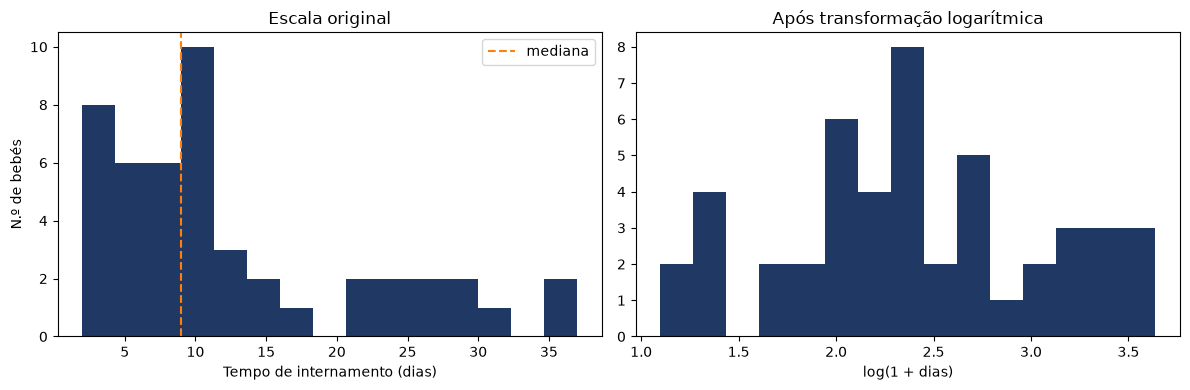

In [9]:
y = episodios["los"].to_numpy()
prev = np.array([np.median(np.delete(y, i)) for i in range(len(y))])   # mediana sem o próprio bebé
mae_base = np.mean(np.abs(y - prev))
rmse_base = np.sqrt(np.mean((y - prev) ** 2))
print(f"Baseline (mediana, leave-one-out): MAE = {mae_base:.2f} dias | RMSE = {rmse_base:.2f} dias")
print(f"Meta da regressão (25% abaixo): MAE <= {mae_base * 0.75:.2f} dias")

# Figura 12 do relatório
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(episodios["los"], bins=15, color="#1f3864")
axes[0].axvline(episodios["los"].median(), color="tab:orange", ls="--", label="mediana")
axes[0].set(title="Escala original", xlabel="Tempo de internamento (dias)", ylabel="N.º de bebés")
axes[0].legend()
axes[1].hist(episodios["log_los"], bins=15, color="#1f3864")
axes[1].set(title="Após transformação logarítmica", xlabel="log(1 + dias)")
fig.tight_layout()
fig.savefig(FIG_DIR / "figura12_tempo_internamento.png", dpi=200, bbox_inches="tight")
plt.show()

### Função de resumo dos sinais vitais

Os três conjuntos usam as **mesmas 20 variáveis** de sinais vitais (Tabela 26). O que muda é o grupo de horas sobre o qual são calculadas: um dia, as primeiras 24 h ou o internamento completo. Por isso escrevemos uma única função, `resumir_sinais`, e usamo-la três vezes. Isto garante que uma variável tem exatamente o mesmo cálculo em todos os conjuntos.

Para cada sinal calcula média, mediana, desvio-padrão, mínimo e máximo (15 variáveis). Junta:

- `horas_registadas`;
- 4 percentagens de horas anormais, calculadas **sobre as horas em que esse sinal foi medido**, para que uma hora sem leitura não conte como hora normal.

In [10]:
NOMES_EST = {"mean": "media", "median": "mediana", "std": "dp", "min": "min", "max": "max"}

def resumir_sinais(df, chaves):
    # df: registos horários; chaves: colunas que definem o grupo (ex.: ["episodio", "data"])
    g = df.groupby(chaves)
    est = g[SINAIS].agg(list(NOMES_EST))                        # 3 sinais x 5 estatísticas
    est.columns = [f"{s}_{NOMES_EST[f]}" for s, f in est.columns]
    est["horas_registadas"] = g.size()

    # Indicadores hora a hora (NaN quando o sinal não foi medido, para não contar como "normal")
    flags = pd.DataFrame({
        "pct_horas_sat_lt90":       (df["sat_o2"] < LIMIAR_HIPOXEMIA).where(df["sat_o2"].notna()),
        "pct_horas_taquicardia":    (df["puls_rate"] > LIMIAR_TAQUICARDIA).where(df["puls_rate"].notna()),
        "pct_horas_bradicardia":    (df["puls_rate"] < LIMIAR_BRADICARDIA).where(df["puls_rate"].notna()),
        "pct_horas_perf_baixa":     (df["perfusion"] < LIMIAR_PERF_BAIXA).where(df["perfusion"].notna()),
    }).astype(float)
    flags[chaves] = df[chaves]
    pct = flags.groupby(chaves).mean() * 100                     # média de 0/1 = proporção
    return est.join(pct)

def tendencia_saturacao(df):
    # Declive da reta sat_o2 ~ hora em cada dia (pontos por hora). Calculado de forma vetorizada:
    # declive = soma((h - média_h) * (s - média_s)) / soma((h - média_h)^2)
    d = df.dropna(subset=["sat_o2"])[["episodio", "data", "hora", "sat_o2"]].copy()
    g = d.groupby(["episodio", "data"])
    d["dh"] = d["hora"] - g["hora"].transform("mean")
    d["ds"] = d["sat_o2"] - g["sat_o2"].transform("mean")
    d["num"], d["den"] = d["dh"] * d["ds"], d["dh"] ** 2
    r = d.groupby(["episodio", "data"]).agg(num=("num", "sum"), den=("den", "sum"), n=("hora", "size"))
    declive = r["num"] / r["den"]
    return declive.where(r["n"] >= MIN_HORAS_TENDENCIA).rename("sat_o2_tendencia")

## 4.4 Integrar dados

Cada conjunto final junta os sinais vitais e as patologias de uma forma diferente, de acordo com o problema.

### Conjunto de classificação (um dia de um bebé)

São quatro passos, os mesmos da secção 4.4.1 do relatório:

1. **Agregar os sinais vitais por bebé e dia.** São as 20 variáveis da função de resumo, mais a tendência da saturação.
2. **Acrescentar o contexto temporal**, sem usar dias futuros:
   - `_delta`: média do dia menos a média do **dia anterior com registo** do mesmo bebé. É em falta no primeiro dia de cada bebé;
   - `dia_internamento`: 1 no primeiro dia em que o bebé aparece (em qualquer ficheiro), 2 no seguinte, e assim por diante;
   - `dia_completo`: 1 se o dia tem pelo menos 12 horas registadas.
3. **Transformar as patologias em colunas 0/1**, uma por grupo, com uma linha por bebé e dia.
4. **Junção à esquerda a partir dos sinais vitais.** Os dias sem patologia ficam com 0; os dias com patologia mas sem sinais vitais ficam de fora, porque não há variáveis para os descrever.

In [11]:
# 1. Agregação diária
diario = resumir_sinais(vit, ["episodio", "data"]).join(tendencia_saturacao(vit)).reset_index()
diario = diario.sort_values(["episodio", "data"]).reset_index(drop=True)

# 2. Contexto temporal
for s in SINAIS:
    diario[f"{s}_delta"] = diario.groupby("episodio")[f"{s}_media"].diff()   # hoje - dia anterior com registo
diario = diario.merge(episodios[["episodio", "primeira_data"]], on="episodio")
diario["dia_internamento"] = (diario["data"] - diario["primeira_data"]).dt.days + 1
diario["dia_completo"] = (diario["horas_registadas"] >= MIN_HORAS_DIA_COMPLETO).astype(int)
diario = diario.drop(columns="primeira_data")

# 3. Patologias em colunas 0/1 (uma linha por bebé e dia)
alvos_dia = (pat.assign(valor=1)
             .pivot_table(index=["episodio", "data"], columns="grupo", values="valor", aggfunc="max", fill_value=0)
             .reindex(columns=["dmh", "ictericia", "anemia", "cmv", "outra"], fill_value=0)
             .add_prefix("pat_").reset_index())

# 4. Junção à esquerda a partir dos sinais vitais
dataset_classificacao = diario.merge(alvos_dia, on=["episodio", "data"], how="left")
dataset_classificacao[ALVOS] = dataset_classificacao[ALVOS].fillna(0).astype(int)

dias_so_patologia = len(alvos_dia.merge(diario[["episodio", "data"]], how="left", indicator=True)
                        .query("_merge == 'left_only'"))
print(f"Dias-bebé com sinais vitais: {len(dataset_classificacao)}")
print(f"Dias sem patologia registada (alvos a 0): {(dataset_classificacao[ALVOS].sum(axis=1) == 0).sum()}")
print(f"Dias com patologia mas sem sinais vitais (fora do conjunto): {dias_so_patologia}")
print("Prevalência dos alvos (% dos dias):", (dataset_classificacao[ALVOS].mean() * 100).round(1).to_dict())

Dias-bebé com sinais vitais: 449
Dias sem patologia registada (alvos a 0): 108
Dias com patologia mas sem sinais vitais (fora do conjunto): 104
Prevalência dos alvos (% dos dias): {'pat_dmh': 52.6, 'pat_ictericia': 26.1, 'pat_anemia': 9.6, 'pat_cmv': 7.1, 'pat_outra': 17.8}


### Conjunto de regressão (um bebé, primeiras 24 h)

Para cada bebé ficamos só com os registos das **primeiras 24 horas a contar do primeiro registo**. É a informação disponível no momento em que a previsão da alta seria útil. Usar o internamento todo seria fuga de informação: o número total de horas registadas tem uma correlação de cerca de 0,99 com o próprio alvo.

As variáveis são:

- as mesmas 20 da função de resumo, calculadas sobre essas 24 h;
- a `hora_admissao`;
- as patologias registadas no **primeiro dia** do bebé: um indicador por cada patologia que aparece em algum primeiro dia, mais `n_patologias_dia1`.

Nota: as "24 horas" contam-se como tempo de relógio. Se houver horas sem registo nesse intervalo, o bebé fica com menos de 24 registos, e isso fica visível em `horas_registadas`.

In [12]:
# Registos dentro das primeiras 24 h de cada bebé
inicio = vit.groupby("episodio")["timestamp"].transform("min")
vit_24h = vit[vit["timestamp"] < inicio + JANELA_REGRESSAO]
reg = resumir_sinais(vit_24h, ["episodio"])

# Patologias do primeiro dia do bebé (primeira data em qualquer ficheiro)
pat_d1 = pat.merge(episodios[["episodio", "primeira_data"]], on="episodio")
pat_d1 = pat_d1[pat_d1["data"] == pat_d1["primeira_data"]]
ind_d1 = (pd.crosstab(pat_d1["episodio"], pat_d1["patologia"]).clip(upper=1)
          .rename(columns=lambda p: f"pat_{SIGLA[p]}_dia1"))
ind_d1 = ind_d1[sorted(ind_d1.columns)]
ind_d1["n_patologias_dia1"] = ind_d1.sum(axis=1)

dataset_regressao = (episodios.set_index("episodio")[["hora_admissao"]]
                     .join(reg)
                     .join(ind_d1)
                     .fillna({c: 0 for c in ind_d1.columns})     # bebés sem patologia no 1.º dia
                     .join(episodios.set_index("episodio")[["los", "log_los", "cens_direita", "cens_esquerda"]])
                     .reset_index())
dataset_regressao[list(ind_d1.columns)] = dataset_regressao[list(ind_d1.columns)].astype(int)

print(f"Bebés: {len(dataset_regressao)} | registos horários usados: {len(vit_24h)}")
print(f"Horas registadas nas primeiras 24 h: mín. {reg['horas_registadas'].min()}, mediana {reg['horas_registadas'].median():.0f}")
print("Patologias presentes no 1.º dia:", list(ind_d1.columns[:-1]))

Bebés: 47 | registos horários usados: 1087
Horas registadas nas primeiras 24 h: mín. 4, mediana 24
Patologias presentes no 1.º dia: ['pat_anemia_dia1', 'pat_cmv_dia1', 'pat_dbp_dia1', 'pat_dmh_dia1', 'pat_ictericia_dia1', 'pat_rge_dia1']


### Conjunto de clustering (um bebé, internamento completo)

Aqui o objetivo é **descrever** o perfil completo de cada bebé, por isso usamos todo o internamento. As variáveis são:

- as 19 estatísticas e percentagens dos sinais vitais. Fica de fora `horas_registadas`, que só mede a duração do internamento e não o estado clínico;
- `frac_dias_pat_<grupo>`: a fração dos dias de internamento (definição revista) em que o bebé teve cada grupo de patologias;
- `n_patologias_distintas`.

`los_validacao` e `cens_direita` ficam no ficheiro **apenas para validar os clusters depois** (por exemplo, os clusters diferem no internamento?). Não podem ser usadas para formar os grupos.

In [13]:
clu = resumir_sinais(vit, ["episodio"]).drop(columns="horas_registadas")

dias_grupo = (pat.drop_duplicates(["episodio", "data", "grupo"])
              .pivot_table(index="episodio", columns="grupo", values="data", aggfunc="count", fill_value=0)
              .reindex(columns=["dmh", "ictericia", "anemia", "cmv", "outra"], fill_value=0))
ep_idx = episodios.set_index("episodio")
frac = (dias_grupo.reindex(ep_idx.index, fill_value=0)          # bebés sem patologia ficam com 0
        .div(ep_idx["los"], axis=0)
        .add_prefix("frac_dias_pat_"))

dataset_clustering = (clu.join(frac)
                      .join(ep_idx[["n_patologias_distintas"]])
                      .join(ep_idx[["los", "cens_direita"]].rename(columns={"los": "los_validacao"}))
                      .reset_index())
print(f"Bebés: {len(dataset_clustering)} | variáveis de agrupamento: {dataset_clustering.shape[1] - 3}")

Bebés: 47 | variáveis de agrupamento: 25


### Verificações da integração

Depois de cada junção confirmamos três coisas, como diz a secção 4.4.1: o número de linhas é o esperado, não há chaves repetidas e os 47 bebés estão presentes. Se alguma falhar, o `assert` interrompe o notebook, em vez de deixar passar um erro para a modelação.

In [14]:
n_bebes = episodios["episodio"].nunique()
verificacoes = [
    ("dataset_classificacao", dataset_classificacao, ["episodio", "data"]),
    ("dataset_regressao", dataset_regressao, ["episodio"]),
    ("dataset_clustering", dataset_clustering, ["episodio"]),
    ("episodios_resumo", episodios, ["episodio"]),
]
for nome, df, chave in verificacoes:
    assert not df.duplicated(chave).any(), f"{nome}: chaves repetidas"
    assert df["episodio"].nunique() == n_bebes, f"{nome}: faltam bebés"
    print(f"✔ {nome}: {len(df)} linhas x {df.shape[1]} colunas, chave única, {n_bebes} bebés")

✔ dataset_classificacao: 449 linhas x 33 colunas, chave única, 47 bebés
✔ dataset_regressao: 47 linhas x 33 colunas, chave única, 47 bebés
✔ dataset_clustering: 47 linhas x 28 colunas, chave única, 47 bebés
✔ episodios_resumo: 47 linhas x 13 colunas, chave única, 47 bebés


## 4.5 Formatar dados

A formatação muda só a forma, nunca o significado:

- nomes das colunas em snake_case, sem acentos nem espaços;
- datas no formato ISO AAAA-MM-DD;
- decimais com ponto e arredondados a 4 casas;
- alvos como inteiros 0/1;
- linhas ordenadas por bebé e data;
- CSV em UTF-8.

O `episodio` fica em todos os conjuntos porque é preciso para a validação agrupada por bebé, mas **não deve ser usado como variável explicativa**.

A imputação, a normalização e o SMOTE **não** são feitos aqui. São ajustados só aos dados de treino, dentro do pipeline de modelação. Fazê-los agora levaria informação dos bebés de teste para o treino.

In [15]:
def formatar(df):
    df = df.copy()
    for c in df.columns:
        if pd.api.types.is_datetime64_any_dtype(df[c]):
            # datas sem hora -> AAAA-MM-DD ; com hora -> AAAA-MM-DD HH:MM
            tem_hora = (df[c].dropna().dt.normalize() != df[c].dropna()).any()
            df[c] = df[c].dt.strftime("%Y-%m-%d %H:%M" if tem_hora else "%Y-%m-%d")
        elif pd.api.types.is_float_dtype(df[c]):
            df[c] = df[c].round(4)
    assert all(re.fullmatch(r"[a-z0-9_]+", c) for c in df.columns), "nome de coluna fora de snake_case"
    ordem = [c for c in ["episodio", "data", "hora"] if c in df.columns]
    return df.sort_values(ordem).reset_index(drop=True)

# Ordem das colunas: identificação -> variáveis -> alvos (fica mais fácil de ler e de separar X e y)
id_c = ["episodio", "data"]
dataset_classificacao = dataset_classificacao[id_c + [c for c in dataset_classificacao if c not in id_c + ALVOS] + ALVOS]
alvos_reg = ["los", "log_los", "cens_direita", "cens_esquerda"]
dataset_regressao = dataset_regressao[["episodio"] + [c for c in dataset_regressao if c not in ["episodio"] + alvos_reg] + alvos_reg]

saidas = {
    "sinais_vitais_limpo.csv": vit[["episodio", "data", "hora", "timestamp"] + SINAIS],
    "patologias_limpo.csv": pat[["episodio", "data", "patologia", "grupo"]],
    "episodios_resumo.csv": episodios,
    "dataset_classificacao.csv": dataset_classificacao,
    "dataset_regressao.csv": dataset_regressao,
    "dataset_clustering.csv": dataset_clustering,
    "relatorio_limpeza.csv": relatorio_limpeza,
}
for nome, df in saidas.items():
    formatar(df).to_csv(OUT_DIR / nome, index=False, encoding="utf-8")
    print(f"{OUT_DIR / nome}: {df.shape[0]} linhas x {df.shape[1]} colunas")

C:\Users\msmou\OneDrive\Ambiente de Trabalho\projeto_aase_grupo5\data\processed\sinais_vitais_limpo.csv: 9789 linhas x 7 colunas
C:\Users\msmou\OneDrive\Ambiente de Trabalho\projeto_aase_grupo5\data\processed\patologias_limpo.csv: 669 linhas x 4 colunas
C:\Users\msmou\OneDrive\Ambiente de Trabalho\projeto_aase_grupo5\data\processed\episodios_resumo.csv: 47 linhas x 13 colunas
C:\Users\msmou\OneDrive\Ambiente de Trabalho\projeto_aase_grupo5\data\processed\dataset_classificacao.csv: 449 linhas x 33 colunas
C:\Users\msmou\OneDrive\Ambiente de Trabalho\projeto_aase_grupo5\data\processed\dataset_regressao.csv: 47 linhas x 33 colunas
C:\Users\msmou\OneDrive\Ambiente de Trabalho\projeto_aase_grupo5\data\processed\dataset_clustering.csv: 47 linhas x 28 colunas
C:\Users\msmou\OneDrive\Ambiente de Trabalho\projeto_aase_grupo5\data\processed\relatorio_limpeza.csv: 10 linhas x 5 colunas


## 4.6 Conjunto de dados final

### Descrição dos conjuntos (Tabela 28)

Para cada conjunto final mostramos a unidade de análise, o número de variáveis explicativas, os alvos e os valores em falta que ficam para o pipeline de modelação.

In [16]:
def descrever_conjunto(nome, df, nao_explicativas):
    expl = [c for c in df.columns if c not in nao_explicativas]
    falta = df[expl].isna().sum()
    print(f"\n=== {nome}: {len(df)} linhas, {len(expl)} variáveis explicativas ===")
    print("Valores em falta:", falta[falta > 0].to_dict() or "nenhum")

descrever_conjunto("Classificação", dataset_classificacao, id_c + ALVOS)
print("Alvos (% dos dias):", (dataset_classificacao[ALVOS].mean() * 100).round(1).to_dict())
descrever_conjunto("Regressão", dataset_regressao, ["episodio"] + alvos_reg)
print(f"Alvo los: {dataset_regressao['los'].min()} a {dataset_regressao['los'].max()} dias, "
      f"mediana {dataset_regressao['los'].median():.0f}, média {dataset_regressao['los'].mean():.1f}")
descrever_conjunto("Clustering", dataset_clustering, ["episodio", "los_validacao", "cens_direita"])


=== Classificação: 449 linhas, 26 variáveis explicativas ===
Valores em falta: {'sat_o2_tendencia': 2, 'sat_o2_delta': 47, 'puls_rate_delta': 47, 'perfusion_delta': 47}
Alvos (% dos dias): {'pat_dmh': 52.6, 'pat_ictericia': 26.1, 'pat_anemia': 9.6, 'pat_cmv': 7.1, 'pat_outra': 17.8}

=== Regressão: 47 linhas, 28 variáveis explicativas ===
Valores em falta: nenhum
Alvo los: 2 a 37 dias, mediana 9, média 12.5

=== Clustering: 47 linhas, 25 variáveis explicativas ===
Valores em falta: nenhum
